# Notebook MAESTRO — Modelos predictivos para identificar spam

**Tesis:** *Modelos predictivos para identificar spam en correos electrónicos*

**Universidad de las Ciencias Informáticas — Facultad de Ciberseguridad**

**Autores:** Alejandro Vázquez Marrero · Jayson Ceballos Hernández

---

## Descripción

Notebook único que ejecuta el experimento completo descrito en el Capítulo II de la memoria. Contiene:

1. **Configuración global** con todas las constantes del Capítulo II.
2. **Tabla de control** con flags para saltar etapas ya completadas.
3. **Setup automático** del entorno (Drive, dependencias).
4. **Pipeline experimental** completo: carga → preprocesamiento → vectorización → clasificadores → modelo híbrido → evaluación → informe.
5. **Cache permanente** de embeddings en Google Drive (descarga única).
6. **Reproducibilidad total** mediante semillas aleatorias fijas.

## Tiempo de ejecución

- **Primera ejecución completa**: 75-90 minutos.
- **Ejecuciones posteriores con cache**: 50-70 minutos.

## Pre-requisitos

1. Cuenta de Google Drive con al menos 15 GB libres.
2. Carpeta `spam_tesis/data/` en Drive con los 5 datasets correctos.
3. Sesión de Colab activa.

**Antes de ejecutar:** revisa la sección 1 (configuración) y ajusta los flags `RUN_*` según necesites.

# 1. Configuración global

## 1.1. Tabla de control: flags para saltar etapas

Si una etapa ya fue ejecutada en una sesión anterior y los archivos están guardados en Drive, ponla en `False` para saltarla.

**Importante:** las etapas posteriores requieren que las anteriores se hayan ejecutado al menos una vez.

In [ ]:
# === FLAGS DE ETAPAS ===
RUN_DATA_LOADING   = True   # carga datasets y genera Tablas 1-6
RUN_PREPROCESSING  = True   # tuberias ingles y turco
RUN_VECTORIZATION  = True   # BoW + TF-IDF + Embeddings + reduccion
RUN_CLASSIFIERS    = True   # Naive Bayes + SVM + RF con GridSearchCV
RUN_HYBRID         = True   # Soft voting + Stacking
RUN_EVALUATION     = True   # matrices, ROC, t-test, Wilcoxon
RUN_FINAL_REPORT   = True   # informe consolidado final

# === EMBEDDINGS EN DRIVE ===
SAVE_EMBEDDINGS_TO_DRIVE = True  # True: descarga unica, ~10 GB de Drive

# === RANDOM STATE ===
RANDOM_STATE = 42

## 1.2. Hiperparámetros y constantes del experimento

In [ ]:
# === PARTICION TRAIN/TEST (II.8.1) ===
TEST_SIZE = 0.20

# === VALIDACION CRUZADA (II.8.2) ===
CV_FOLDS = 5

# === PREPROCESAMIENTO (II.4) ===
MIN_TOKEN_LENGTH = 3

# === VECTORIZACION (II.5) ===
NGRAM_RANGE = (1, 2)
MAX_FEATURES = 10000
MIN_DF = 2
MAX_DF = 0.95
EMBEDDING_DIM = 300

# === REDUCCION DIMENSIONAL (II.5.4) ===
SVD_N_COMPONENTS = 300
PCA_N_COMPONENTS = 100
PCA_SPAMBASE = 30

# === HIPERPARAMETROS DE CLASIFICADORES (II.6) ===
NB_PARAMS = {'alpha': [0.01, 0.1, 0.5, 1.0, 2.0]}
SVM_PARAMS = {'C': [0.1, 1, 10, 100], 'gamma': ['scale', 'auto', 0.01, 0.1]}
RF_PARAMS = {'max_depth': [10, 20, None], 'min_samples_split': [2, 5, 10]}

SVM_FIXED = {
    'kernel': 'rbf',
    'probability': True,
    'class_weight': 'balanced',
    'random_state': RANDOM_STATE
}
RF_FIXED = {
    'n_estimators': 100,
    'criterion': 'gini',
    'max_features': 'sqrt',
    'class_weight': 'balanced_subsample',
    'random_state': RANDOM_STATE,
    'n_jobs': -1
}

# === GRIDSEARCHCV (II.6.4) ===
GRID_CV_FOLDS = 5
GRID_SCORING = 'f1_macro'

# === SMOTE (II.4.6) ===
SMOTE_K = 5

# === ANALISIS ESTADISTICO (II.8.4) ===
ALPHA_SIGNIFICANCE = 0.05

print('[OK] Hiperparametros configurados.')

[OK] Hiperparametros configurados.


## 1.3. Configuración de los datasets

In [ ]:
DATASETS_CONFIG = {
    'sms_spam': {
        'filename': 'sms_spam.csv',
        'language': 'en',
        'format': 'text',
        'text_column': 1,
        'label_column': 0,
        'label_map': {'ham': 0, 'spam': 1},
        'encoding': 'latin-1',
        'separator': '\t',
        'header': None
    },
    'spambase': {
        'filename': 'spambase.data',
        'language': 'numeric',
        'format': 'numeric',
        'n_features': 57,
        'separator': ','
    },
    'youtube_shakira': {
        'filename': 'youtube_shakira.csv',
        'language': 'en',
        'format': 'text',
        'text_column': 0,
        'label_column': 1,
        'label_map': {'0': 0, '1': 1},
        'encoding': 'utf-8',
        'separator': ',',
        'header': None
    },
    'trspam': {
        'filename': 'trspam.csv',
        'language': 'tr',
        'format': 'text',
        'text_column': 0,
        'label_column': 1,
        'label_map': {'ham': 0, 'spam': 1},
        'encoding': 'utf-8',
        'separator': ',',
        'header': None
    },
    'spam_ham_email': {
        'filename': 'spam_ham_email.csv',
        'language': 'en',
        'format': 'text',
        'text_column': 0,
        'label_column': 1,
        'label_map': {'0': 0, '1': 1},
        'encoding': 'utf-8',
        'separator': ',',
        'header': None
    }
}

COMPATIBILITY = {
    'naive_bayes': {
        'bow': True, 'tfidf': True,
        'emb': False, 'bow_svd': False, 'tfidf_svd': False, 'emb_pca': False
    },
    'svm_rbf': {
        'bow': True, 'tfidf': True,
        'emb': True, 'bow_svd': True, 'tfidf_svd': True, 'emb_pca': True
    },
    'random_forest': {
        'bow': True, 'tfidf': True,
        'emb': True, 'bow_svd': True, 'tfidf_svd': True, 'emb_pca': True
    }
}

MODEL_LABELS = {
    'naive_bayes': 'Naive Bayes',
    'svm_rbf': 'SVM RBF',
    'random_forest': 'Random Forest',
    'soft_voting': 'Soft Voting',
    'stacking': 'Stacking'
}

MODEL_COLORS = {
    'naive_bayes': '#1f77b4',
    'svm_rbf': '#ff7f0e',
    'random_forest': '#2ca02c',
    'soft_voting': '#d62728',
    'stacking': '#9467bd'
}

print(f'[OK] Configurados {len(DATASETS_CONFIG)} datasets.')

[OK] Configurados 5 datasets.


# 2. Setup del entorno

Montaje de Drive, creación de carpetas e instalación de dependencias.

## 2.1. Montaje de Google Drive y estructura de carpetas

In [ ]:
from google.colab import drive
from pathlib import Path
import os

if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

PROJECT_ROOT = Path('/content/drive/MyDrive/spam_tesis')
DATA_DIR = PROJECT_ROOT / 'data'
MODELS_DIR = PROJECT_ROOT / 'models'
EMBEDDINGS_DRIVE_DIR = MODELS_DIR / 'embeddings'

RESULTS_DIR = PROJECT_ROOT / 'results'
PROCESSED_DIR = RESULTS_DIR / 'processed'
VECTORS_DIR = RESULTS_DIR / 'vectors'
RESULTS_MODELS_DIR = RESULTS_DIR / 'models'
METRICS_DIR = RESULTS_DIR / 'metrics'
FIGURES_DIR = RESULTS_DIR / 'figures'
CONFUSION_DIR = FIGURES_DIR / 'confusion_matrices'
ROC_DIR = FIGURES_DIR / 'roc_curves'
REPORT_DIR = RESULTS_DIR / 'report'

EMBEDDINGS_CACHE_DIR = Path('/content/embeddings_cache')

for path in [DATA_DIR, MODELS_DIR, EMBEDDINGS_DRIVE_DIR, PROCESSED_DIR, VECTORS_DIR,
             RESULTS_MODELS_DIR, METRICS_DIR, FIGURES_DIR, CONFUSION_DIR, ROC_DIR,
             REPORT_DIR, EMBEDDINGS_CACHE_DIR]:
    path.mkdir(parents=True, exist_ok=True)

expected_datasets = ['sms_spam.csv', 'spambase.data', 'youtube_shakira.csv',
                     'trspam.csv', 'spam_ham_email.csv']
missing = [d for d in expected_datasets if not (DATA_DIR / d).exists()]

print(f'[OK] PROJECT_ROOT: {PROJECT_ROOT}')
if missing:
    raise FileNotFoundError(
        f'Faltan datasets en {DATA_DIR}: {missing}'
    )
else:
    print(f'[OK] Los 5 datasets estan presentes en {DATA_DIR}.')

Mounted at /content/drive
[OK] PROJECT_ROOT: /content/drive/MyDrive/spam_tesis
[OK] Los 5 datasets estan presentes en /content/drive/MyDrive/spam_tesis/data.


## 2.2. Instalación de dependencias

In [ ]:
%pip install -q imbalanced-learn==0.14.1
%pip install -q zeyrek==0.1.3
!pip install -q gensim
print('[OK] gensim instalado.')

import spacy
try:
    spacy.load('en_core_web_sm')
    print('[OK] Modelo en_core_web_sm ya disponible.')
except OSError:
    print('Descargando en_core_web_sm...')
    !python -m spacy download en_core_web_sm --quiet
    print('[OK] Descargado.')

import nltk
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)

from nltk.corpus import stopwords
n_en = len(stopwords.words('english'))
n_tr = len(stopwords.words('turkish'))
print(f'[OK] Stopwords ingles: {n_en}, turco: {n_tr}')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 931.0/931.0 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 54.4 MB/s eta 0:00:00
[OK] gensim instalado.
[OK] Modelo en_core_web_sm ya disponible.
[OK] Stopwords ingles: 198, turco: 53


## 2.3. Importaciones globales y funciones reutilizables

In [ ]:
import json
import pickle
import time
import gc
import re
import string
import warnings
import urllib.request
import gzip
import shutil
from datetime import datetime
from itertools import combinations
from typing import List

import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy import stats
import joblib

import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score, precision_score, recall_score, accuracy_score,
    roc_auc_score, roc_curve, auc, confusion_matrix
)
from sklearn.base import clone
from imblearn.over_sampling import SMOTE
from gensim.models import KeyedVectors
import zeyrek

warnings.filterwarnings('ignore')

# Funciones reutilizables
def load_representation(dataset_name, repr_type):
    """Carga una representacion vectorizada desde disco."""
    if repr_type in ['bow', 'tfidf']:
        train_path = VECTORS_DIR / f'{dataset_name}_{repr_type}_train.npz'
        test_path = VECTORS_DIR / f'{dataset_name}_{repr_type}_test.npz'
        if not train_path.exists():
            return None, None
        return sp.load_npz(train_path), sp.load_npz(test_path)
    else:
        path = VECTORS_DIR / f'{dataset_name}_{repr_type}.npz'
        if not path.exists():
            return None, None
        data = np.load(path)
        return data['X_train'], data['X_test']


def apply_smote(X_train, y_train, k_neighbors=SMOTE_K):
    """Aplica SMOTE al conjunto de entrenamiento si esta desbalanceado."""
    n_minority = min(np.bincount(y_train))
    if n_minority <= k_neighbors:
        return X_train, y_train
    n_majority = max(np.bincount(y_train))
    if n_minority / n_majority >= 0.95:
        return X_train, y_train
    smote = SMOTE(random_state=RANDOM_STATE, k_neighbors=k_neighbors)
    return smote.fit_resample(X_train, y_train)


print('[OK] Importaciones y funciones reutilizables listas.')

[OK] Importaciones y funciones reutilizables listas.


# 3. Carga y caracterización de datasets

Carga los 5 datasets, los normaliza al formato estándar y genera las Tablas 1-6 del Capítulo II.

ETAPA 1: Carga de datasets
  [OK] sms_spam             | Total:  5169 | Spam:  653 ( 12.6%)
  [OK] spambase             | Total:  4601 | Spam: 1813 ( 39.4%)
  [OK] youtube_shakira      | Total:   331 | Spam:  150 ( 45.3%)
  [OK] trspam               | Total:   634 | Spam:  223 ( 35.2%)
  [OK] spam_ham_email       | Total:  4993 | Spam: 1462 ( 29.3%)

Tabla 1: Estadisticas del Dataset sms_spam
           Atributo       Valor
 Nombre del Dataset    sms_spam
            Dominio         SMS
Total de Instancias        5169
    Instancias Spam         653
     Instancias Ham        4516
    Porcentaje Spam     12.63 %
     Porcentaje Ham     87.37 %
Longitud media Spam         138
 Longitud media Ham          70
 Formato de entrada Texto crudo
  Tipo de atributos       Texto
             Idioma          EN

Tabla 2: Estadisticas del Dataset spambase
           Atributo    Valor
 Nombre del Dataset spambase
            Dominio   Correo
Total de Instancias     4601
    Instancias Spam     1813

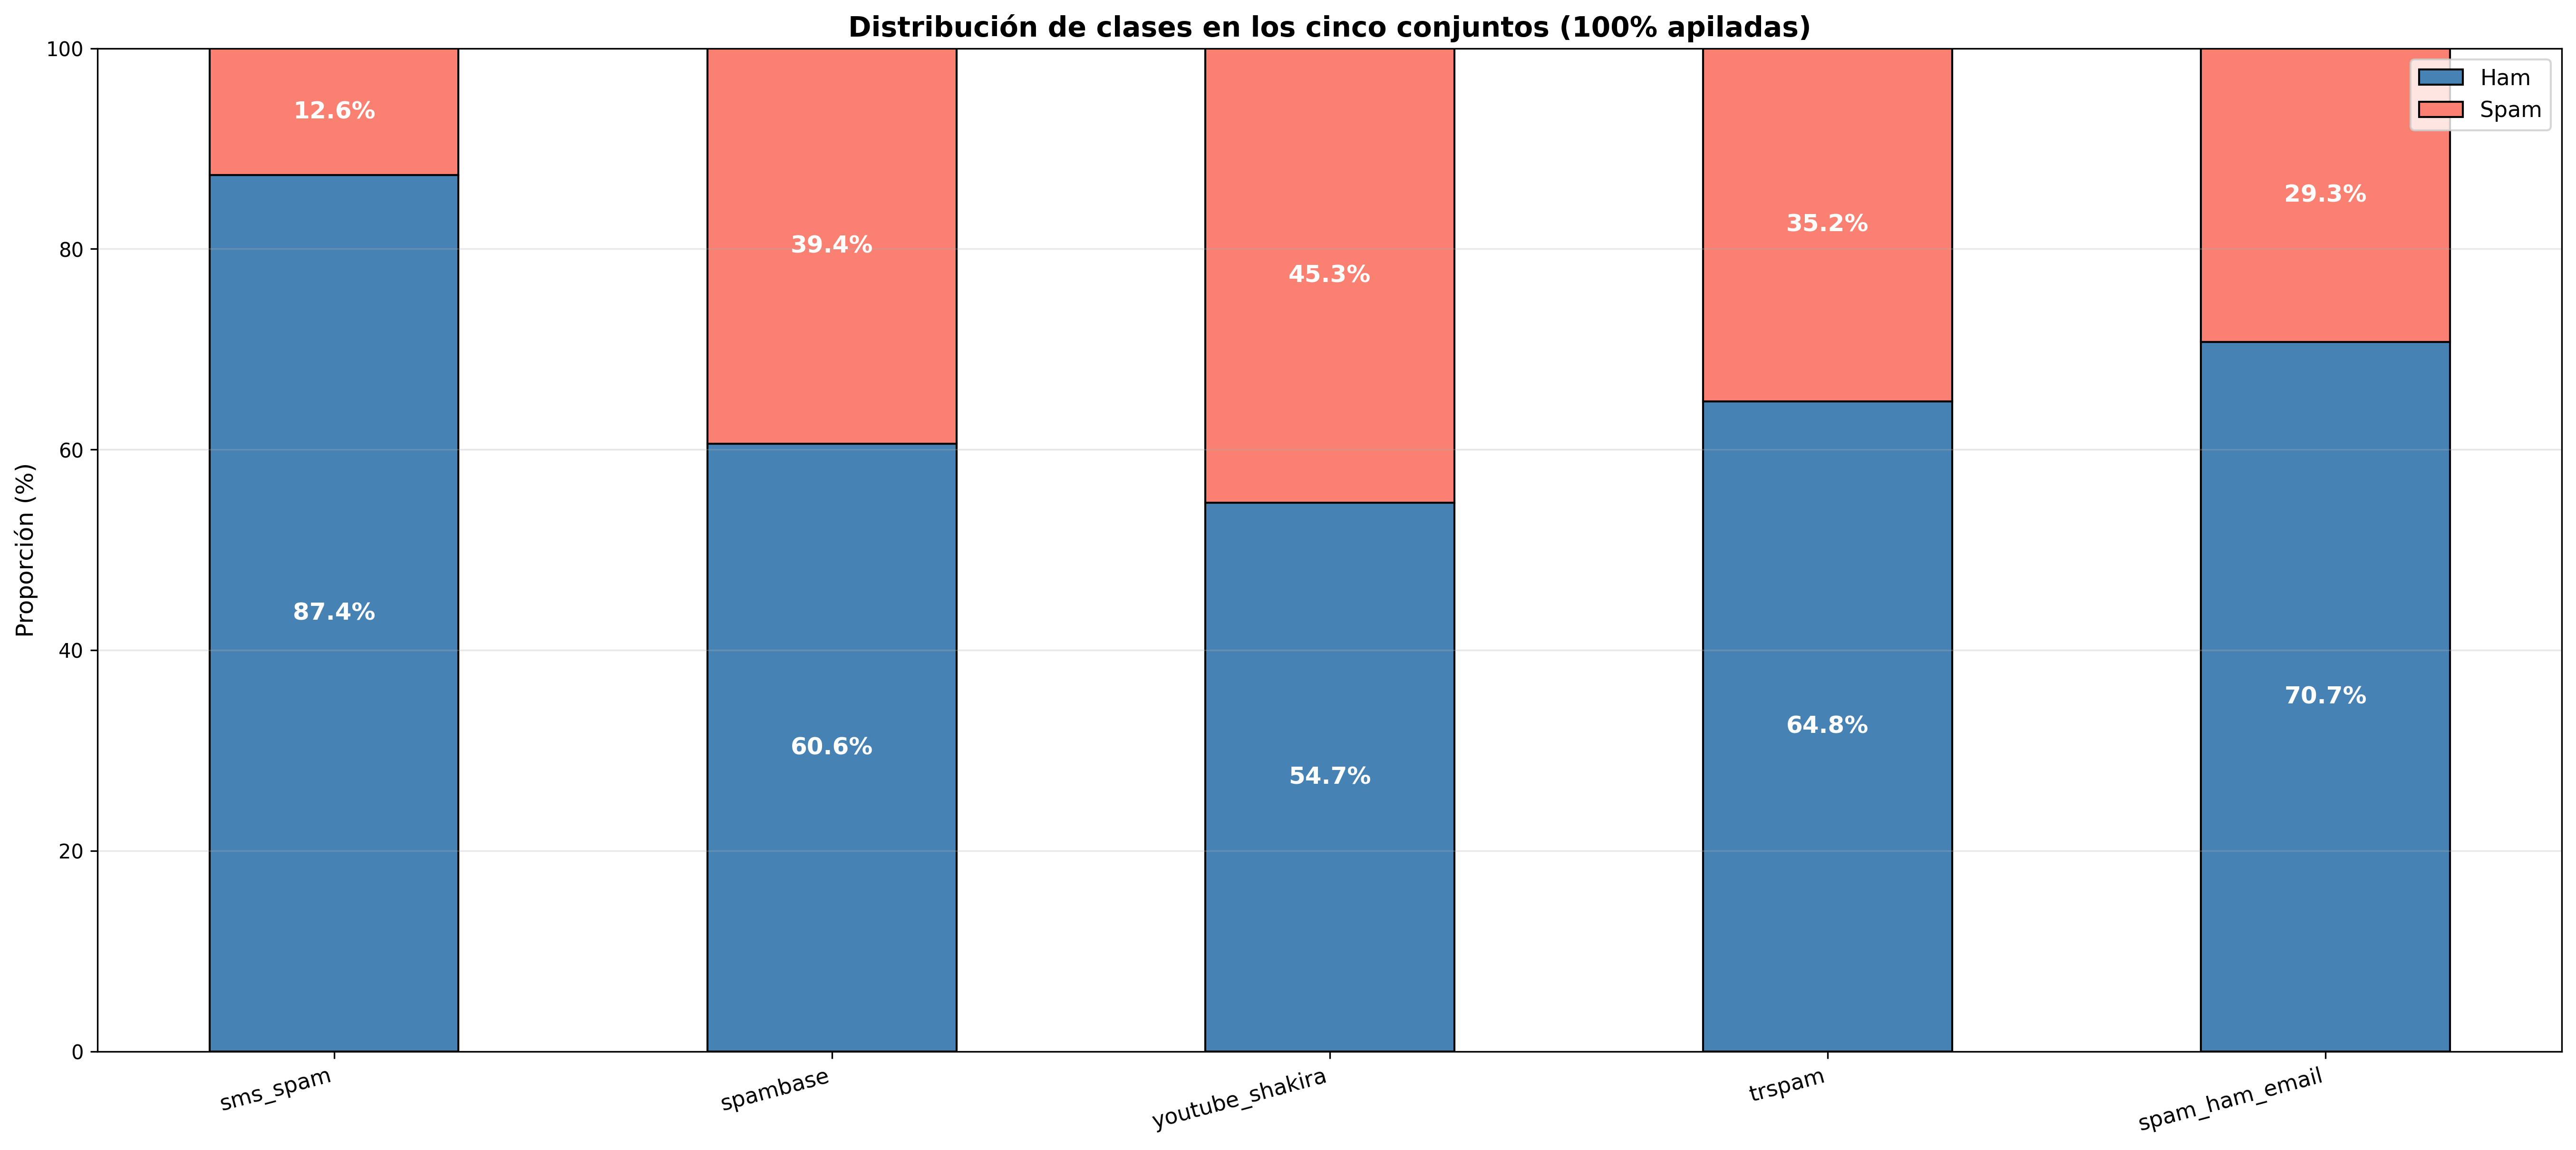


[OK] ETAPA 1 completada.


In [ ]:
if RUN_DATA_LOADING:
    print('=' * 70)
    print('ETAPA 1: Carga de datasets')
    print('=' * 70)

    def load_textual_dataset(file_path, config, dataset_name):
        explicit_names = None
        if isinstance(config['text_column'], int) and isinstance(config['label_column'], int):
            explicit_names = [config['label_column'], config['text_column']]
            explicit_names = sorted(list(set(explicit_names)))
            if len(explicit_names) > 2:
                explicit_names = list(range(max(explicit_names) + 1))
            elif len(explicit_names) == 1:
                explicit_names = list(range(explicit_names[0] + 1))
            else:
                explicit_names = [0, 1]

        df = pd.read_csv(
            file_path,
            encoding=config['encoding'],
            sep=config['separator'],
            on_bad_lines='skip',
            header=config.get('header', None),
            names=explicit_names
        )
        text_col = config['text_column']
        label_col = config['label_column']
        if text_col not in df.columns or label_col not in df.columns:
            raise ValueError(
                f'Columnas no encontradas en {dataset_name}. '
                f'Disponibles: {list(df.columns)}'
            )
        df = df[[text_col, label_col]].copy()
        df.columns = ['text', 'label']
        df['label'] = df['label'].map(config['label_map'])
        df = df.dropna(subset=['text', 'label']).reset_index(drop=True)
        df['label'] = df['label'].astype(int)
        df['text'] = df['text'].astype(str)
        df = df.drop_duplicates(subset=['text']).reset_index(drop=True)
        return df

    def load_spambase(file_path, config):
        df = pd.read_csv(file_path, header=None)
        n_features = config['n_features']
        if df.shape[1] != n_features + 1:
            raise ValueError(f'Spambase debe tener {n_features + 1} columnas')
        feature_cols = [f'f{i}' for i in range(n_features)]
        df.columns = feature_cols + ['label']
        df['label'] = df['label'].astype(int)
        return df

    datasets = {}
    for name, config in DATASETS_CONFIG.items():
        file_path = DATA_DIR / config['filename']
        if config['format'] == 'numeric':
            df = load_spambase(file_path, config)
        else:
            df = load_textual_dataset(file_path, config, name)
        datasets[name] = df
        n_total = len(df)
        n_spam = (df['label'] == 1).sum()
        pct = n_spam / n_total * 100
        print(f'  [OK] {name:<20} | Total: {n_total:>5} | Spam: {n_spam:>4} ({pct:5.1f}%)')

    # Guardar DataFrames raw
    for name, df in datasets.items():
        df.to_pickle(PROCESSED_DIR / f'{name}_raw.pkl')

    with open(PROCESSED_DIR / 'datasets_config.pkl', 'wb') as f:
        pickle.dump(DATASETS_CONFIG, f)

    domain_map = {
        'sms_spam': 'SMS', 'spambase': 'Correo',
        'youtube_shakira': 'Comentario', 'trspam': 'Correo',
        'spam_ham_email': 'Correo'
    }

    rows = []
    all_stats = {}
    for name, df in datasets.items():
        config = DATASETS_CONFIG[name]
        n_total = len(df)
        n_spam = int((df['label'] == 1).sum())
        n_ham = int((df['label'] == 0).sum())
        pct_spam = round((n_spam / n_total) * 100, 2)

        if config['format'] == 'text':
            len_spam = int(df.loc[df['label'] == 1, 'text'].str.len().mean())
            len_ham = int(df.loc[df['label'] == 0, 'text'].str.len().mean())
        else:
            len_spam = 'N/A'
            len_ham = 'N/A'

        rows.append({
            'Conjunto': name,
            'Dominio': domain_map[name],
            'Idioma': config['language'].upper() if config['language'] != 'numeric' else 'N/A',
            'Total': n_total,
            '% spam': f'{pct_spam} %',
            'Long. spam': len_spam,
            'Long. ham': len_ham,
            'Tipo de entrada': 'Texto crudo' if config['format'] == 'text' else 'Numérico',
        })

        all_stats[name] = {
            'total_instances': n_total,
            'spam_instances': n_spam,
            'ham_instances': n_ham,
            'spam_percentage': pct_spam,
            'ham_instances_count': n_ham,
            'mean_spam_length': len_spam,
            'mean_ham_length': len_ham,
            'input_format': 'Texto crudo' if config['format'] == 'text' else 'Numérico',
        }

    # Tablas 1-5: estadísticas individuales
    for i, (name, stats) in enumerate(all_stats.items()):
        df_individual_table = pd.DataFrame({
            'Atributo': [
                'Nombre del Dataset', 'Dominio', 'Total de Instancias',
                'Instancias Spam', 'Instancias Ham', 'Porcentaje Spam', 'Porcentaje Ham',
                'Longitud media Spam', 'Longitud media Ham',
                'Formato de entrada', 'Tipo de atributos', 'Idioma'
            ],
            'Valor': [
                name,
                domain_map.get(name, 'N/A'),
                stats['total_instances'],
                stats['spam_instances'],
                stats['ham_instances_count'],
                f"{stats['spam_percentage']:.2f} %",
                f"{(100 - stats['spam_percentage']):.2f} %",
                stats['mean_spam_length'],
                stats['mean_ham_length'],
                stats['input_format'],
                'Numérico' if DATASETS_CONFIG[name]['format'] == 'numeric' else 'Texto',
                DATASETS_CONFIG[name]['language'].upper() if DATASETS_CONFIG[name]['language'] != 'numeric' else 'N/A'
            ]
        })
        print(f'\nTabla {i+1}: Estadisticas del Dataset {name}')
        print('=' * 60)
        print(df_individual_table.to_string(index=False))
        print('=' * 60)
        df_individual_table.to_csv(METRICS_DIR / f'tabla{i+1}_{name}_stats.csv', index=False)

    # Tabla 6: comparativa
    df_tabla6 = pd.DataFrame(rows)
    print('\nTabla 6: Comparativa de los cinco conjuntos de datos')
    print('=' * 100)
    print(df_tabla6.to_string(index=False))
    print('=' * 100)

    df_tabla6.to_csv(METRICS_DIR / 'tabla6_comparativa.csv', index=False)
    with open(METRICS_DIR / 'datasets_statistics.json', 'w', encoding='utf-8') as f:
        json.dump(all_stats, f, indent=2, ensure_ascii=False)

    # Visualización
    print('\nGenerando figura de distribución de clases...')
    plt.rcParams['figure.dpi'] = 300
    plt.rcParams['savefig.dpi'] = 600

    fig, ax = plt.subplots(figsize=(18, 8))
    names = list(datasets.keys())
    ham_counts = np.array([int((datasets[n]['label'] == 0).sum()) for n in names])
    spam_counts = np.array([int((datasets[n]['label'] == 1).sum()) for n in names])
    totals = ham_counts + spam_counts
    ham_pct = ham_counts / totals * 100
    spam_pct = spam_counts / totals * 100
    x = np.arange(len(names))
    w = 0.5

    bars_ham = ax.bar(x, ham_pct, w, label='Ham', color='steelblue', edgecolor='black')
    bars_spam = ax.bar(x, spam_pct, w, bottom=ham_pct, label='Spam', color='salmon', edgecolor='black')

    for i in range(len(names)):
        if ham_pct[i] > 5:
            ax.text(x[i], ham_pct[i] / 2, f'{ham_pct[i]:.1f}%',
                    ha='center', va='center', fontsize=12, color='white', fontweight='bold')
        if spam_pct[i] > 5:
            ax.text(x[i], ham_pct[i] + spam_pct[i] / 2, f'{spam_pct[i]:.1f}%',
                    ha='center', va='center', fontsize=12, color='white', fontweight='bold')

    ax.set_xticks(x)
    ax.set_xticklabels(names, rotation=15, ha='right', fontsize=11)
    ax.set_ylabel('Proporción (%)', fontsize=12)
    ax.set_ylim(0, 100)
    ax.set_title('Distribución de clases en los cinco conjuntos (100% apiladas)',
                 fontsize=14, fontweight='bold')
    ax.legend(loc='upper right', fontsize=11)
    ax.grid(axis='y', alpha=0.3)

    plt.tight_layout(pad=0.5)
    plt.savefig(FIGURES_DIR / 'distribucion_clases_datasets_hd.png',
                dpi=600, bbox_inches='tight', pad_inches=0.1)
    plt.show()

    print('\n[OK] ETAPA 1 completada.')

else:
    print('[SKIP] Etapa 1 saltada (RUN_DATA_LOADING=False).')
    # Cargar lo guardado
    datasets = {}
    for name in DATASETS_CONFIG.keys():
        datasets[name] = pd.read_pickle(PROCESSED_DIR / f'{name}_raw.pkl')
    print(f'  Recuperados {len(datasets)} datasets desde Drive.')

# 4. Preprocesamiento

Aplica las tuberías inglés (spaCy) y turco (Zeyrek) descritas en el epígrafe II.4.

In [ ]:
if RUN_PREPROCESSING:
    print('=' * 70)
    print('ETAPA 2: Preprocesamiento')
    print('=' * 70)

    nlp_en = spacy.load('en_core_web_sm', disable=['parser', 'ner'])
    stopwords_en = set(stopwords.words('english'))
    stopwords_tr = set(stopwords.words('turkish'))
    lemmatizer_tr = zeyrek.MorphAnalyzer()

    SPECIAL_TOKENS = {'<URL>', '<EMAIL>'}

    def normalize_text_en(text):
        text = text.lower()
        text = re.sub(r'<[^>]+>', ' ', text)
        text = re.sub(r'http[s]?://\S+|www\.\S+', ' <URL> ', text)
        text = re.sub(r'\S+@\S+\.\S+', ' <EMAIL> ', text)
        text = re.sub(r'\d+', ' ', text)
        text = text.translate(str.maketrans('', '', string.punctuation))
        text = re.sub(r'\s+', ' ', text).strip()
        return text

    def normalize_text_tr(text):
        text = text.lower()
        text = re.sub(r'<[^>]+>', ' ', text)
        text = re.sub(r'http[s]?://\S+|www\.\S+', ' <URL> ', text)
        text = re.sub(r'\S+@\S+\.\S+', ' <EMAIL> ', text)
        text = re.sub(r'\d+', ' ', text)
        text = re.sub(r'[^\w\sçğıöşüÇĞİÖŞÜ<>]', ' ', text)
        text = re.sub(r'\s+', ' ', text).strip()
        return text

    def preprocess_text_en(text):
        normalized = normalize_text_en(text)
        doc = nlp_en(normalized)
        tokens = []
        for token in doc:
            if token.text in SPECIAL_TOKENS:
                tokens.append(token.text)
                continue
            if token.is_space or token.is_punct:
                continue
            if token.lemma_ in stopwords_en:
                continue
            if len(token.lemma_) < MIN_TOKEN_LENGTH:
                continue
            tokens.append(token.lemma_)
        return ' '.join(tokens)

    def preprocess_text_tr(text):
        normalized = normalize_text_tr(text)
        raw_tokens = normalized.split()
        tokens = []
        for tok in raw_tokens:
            if tok in SPECIAL_TOKENS:
                tokens.append(tok)
                continue
            if tok in stopwords_tr or len(tok) < MIN_TOKEN_LENGTH:
                continue
            try:
                analyses = lemmatizer_tr.lemmatize(tok)
                if analyses and len(analyses[0]) > 1 and analyses[0][1]:
                    tokens.append(analyses[0][1][0].lower())
                else:
                    tokens.append(tok)
            except Exception:
                tokens.append(tok)
        return ' '.join(tokens)

    datasets_clean = {}
    for name, df in datasets.items():
        config = DATASETS_CONFIG[name]
        language = config['language']

        print(f'\n  Procesando {name} ({language}, {len(df)} ejemplos)...')
        start = time.time()

        if language == 'numeric':
            datasets_clean[name] = df.copy()
        elif language == 'en':
            df_proc = df.copy()
            tqdm.pandas(desc='  ' + name)
            df_proc['text'] = df_proc['text'].progress_apply(preprocess_text_en)
            df_proc = df_proc[df_proc['text'].str.len() > 0].reset_index(drop=True)
            datasets_clean[name] = df_proc
        elif language == 'tr':
            df_proc = df.copy()
            tqdm.pandas(desc='  ' + name)
            df_proc['text'] = df_proc['text'].progress_apply(preprocess_text_tr)
            df_proc = df_proc[df_proc['text'].str.len() > 0].reset_index(drop=True)
            datasets_clean[name] = df_proc

        elapsed = time.time() - start
        print(f'  [OK] {name}: {len(datasets_clean[name])} ejemplos en {elapsed:.1f}s')

    # Guardar
    for name, df in datasets_clean.items():
        df.to_pickle(PROCESSED_DIR / f'{name}_clean.pkl')

    print('\n[OK] ETAPA 2 completada.')
else:
    print('[SKIP] Etapa 2 saltada.')
    datasets_clean = {}
    for name in DATASETS_CONFIG.keys():
        datasets_clean[name] = pd.read_pickle(PROCESSED_DIR / f'{name}_clean.pkl')
    print(f'  Recuperados {len(datasets_clean)} datasets preprocesados.')

# 5. Vectorización

Genera BoW, TF-IDF, Word Embeddings y aplica reducción de dimensionalidad. Los modelos preentrenados se cachean en Drive (descarga única).

## 5.1. Particiones train/test

In [ ]:
splits = {}

for name in DATASETS_CONFIG.keys():
    df = datasets_clean[name]
    config = DATASETS_CONFIG[name]

    if config['format'] == 'numeric':
        feature_cols = [c for c in df.columns if c != 'label']
        X = df[feature_cols].values
    else:
        X = df['text'].values
    y = df['label'].values

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
    )

    splits[name] = {
        'X_train': X_train, 'X_test': X_test,
        'y_train': y_train, 'y_test': y_test
    }
    print(f'  [OK] {name:<20} | train: {len(X_train)} | test: {len(X_test)}')

with open(PROCESSED_DIR / 'splits.pkl', 'wb') as f:
    pickle.dump(splits, f)

print('\n[OK] Particiones generadas y guardadas.')

## 5.2. Vectorización BoW y TF-IDF

In [ ]:
if RUN_VECTORIZATION:
    print('=' * 70)
    print('ETAPA 3: Vectorizacion')
    print('=' * 70)

    bow_vectorizers = {}
    tfidf_vectorizers = {}
    bow_vectors = {}
    tfidf_vectors = {}

    for name in DATASETS_CONFIG.keys():
        config = DATASETS_CONFIG[name]
        if config['format'] == 'numeric':
            continue

        # BoW
        cv = CountVectorizer(
            ngram_range=NGRAM_RANGE, max_features=MAX_FEATURES,
            min_df=MIN_DF, max_df=MAX_DF, lowercase=False
        )
        X_train_bow = cv.fit_transform(splits[name]['X_train'])
        X_test_bow = cv.transform(splits[name]['X_test'])
        bow_vectors[name] = {'X_train': X_train_bow, 'X_test': X_test_bow}
        bow_vectorizers[name] = cv

        # TF-IDF
        tv = TfidfVectorizer(
            ngram_range=NGRAM_RANGE, max_features=MAX_FEATURES,
            min_df=MIN_DF, max_df=MAX_DF, sublinear_tf=True, lowercase=False
        )
        X_train_tfidf = tv.fit_transform(splits[name]['X_train'])
        X_test_tfidf = tv.transform(splits[name]['X_test'])
        tfidf_vectors[name] = {'X_train': X_train_tfidf, 'X_test': X_test_tfidf}
        tfidf_vectorizers[name] = tv

        # Guardar
        sp.save_npz(VECTORS_DIR / f'{name}_bow_train.npz', X_train_bow)
        sp.save_npz(VECTORS_DIR / f'{name}_bow_test.npz', X_test_bow)
        sp.save_npz(VECTORS_DIR / f'{name}_tfidf_train.npz', X_train_tfidf)
        sp.save_npz(VECTORS_DIR / f'{name}_tfidf_test.npz', X_test_tfidf)

        print(f'  [OK] {name:<20} | BoW: {X_train_bow.shape} | TF-IDF: {X_train_tfidf.shape}')

## 5.3. Descarga y caching de Word2Vec en Drive

Si `SAVE_EMBEDDINGS_TO_DRIVE = True`, el modelo Word2Vec GoogleNews 300d se descarga **una sola vez** a `models/embeddings/` en Drive. En sesiones posteriores se copia rápidamente desde Drive a `/content/embeddings_cache/` para acceso veloz.

In [ ]:
if RUN_VECTORIZATION:
    W2V_FILENAME = 'GoogleNews-vectors-negative300.bin'
    W2V_DRIVE_PATH = EMBEDDINGS_DRIVE_DIR / W2V_FILENAME
    W2V_CACHE_PATH = EMBEDDINGS_CACHE_DIR / W2V_FILENAME

    if W2V_CACHE_PATH.exists():
        print(f'[OK] Word2Vec ya en cache local: {W2V_CACHE_PATH}')
    elif W2V_DRIVE_PATH.exists():
        print(f'Copiando Word2Vec desde Drive a cache local...')
        shutil.copy(W2V_DRIVE_PATH, W2V_CACHE_PATH)
        print(f'[OK] Copiado: {W2V_CACHE_PATH}')
    else:
        print('Descargando Word2Vec GoogleNews 300d (~3.5 GB, 5-8 min)...')
        import gensim.downloader as api
        w2v_temp = api.load('word2vec-google-news-300')
        w2v_temp.save_word2vec_format(str(W2V_CACHE_PATH), binary=True)
        del w2v_temp
        gc.collect()
        print(f'[OK] Descargado: {W2V_CACHE_PATH}')

        if SAVE_EMBEDDINGS_TO_DRIVE:
            print('Copiando a Drive para uso futuro...')
            shutil.copy(W2V_CACHE_PATH, W2V_DRIVE_PATH)
            print(f'[OK] Guardado en Drive: {W2V_DRIVE_PATH}')

    print(f'\nCargando Word2Vec en memoria...')
    start = time.time()
    w2v_en = KeyedVectors.load_word2vec_format(str(W2V_CACHE_PATH), binary=True)
    print(f'[OK] Cargado en {time.time() - start:.1f}s | Vocab: {len(w2v_en.key_to_index):,}')

## 5.4. Generar embeddings para datasets en inglés

In [ ]:
if RUN_VECTORIZATION:
    def doc_to_weighted_emb(text, w2v_model, idf_dict):
        tokens = text.split()
        weighted = []
        weights = []
        for tok in tokens:
            if tok in w2v_model.key_to_index:
                idf = idf_dict.get(tok, 1.0)
                weighted.append(w2v_model[tok] * idf)
                weights.append(idf)
        if not weighted:
            return np.zeros(EMBEDDING_DIM, dtype=np.float32)
        return np.sum(weighted, axis=0) / np.sum(weights)

    def gen_embeddings(X_array, w2v_model, tfidf_vec):
        feature_names = tfidf_vec.get_feature_names_out()
        idf_dict = dict(zip(feature_names, tfidf_vec.idf_))
        emb = np.zeros((len(X_array), EMBEDDING_DIM), dtype=np.float32)
        for i, text in enumerate(tqdm(X_array, desc='  embeddings')):
            emb[i] = doc_to_weighted_emb(text, w2v_model, idf_dict)
        return emb

    embedding_vectors = {}
    english_datasets = [n for n, c in DATASETS_CONFIG.items() if c.get('language') == 'en']

    for name in english_datasets:
        print(f'\n  Embeddings de {name}...')
        X_train_emb = gen_embeddings(splits[name]['X_train'], w2v_en, tfidf_vectorizers[name])
        X_test_emb = gen_embeddings(splits[name]['X_test'], w2v_en, tfidf_vectorizers[name])
        embedding_vectors[name] = {'X_train': X_train_emb, 'X_test': X_test_emb}
        np.savez(VECTORS_DIR / f'{name}_emb.npz', X_train=X_train_emb, X_test=X_test_emb)

    del w2v_en
    gc.collect()
    print('\n[OK] Word2Vec liberado de memoria.')

## 5.5. Descarga y caching de FastText turco en Drive

In [ ]:
if RUN_VECTORIZATION:
    FT_FILENAME = 'cc.tr.300.vec'
    FT_GZ_FILENAME = 'cc.tr.300.vec.gz'
    FT_DRIVE_PATH = EMBEDDINGS_DRIVE_DIR / FT_FILENAME
    FT_CACHE_PATH = EMBEDDINGS_CACHE_DIR / FT_FILENAME
    FT_CACHE_GZ = EMBEDDINGS_CACHE_DIR / FT_GZ_FILENAME
    FT_URL = 'https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.tr.300.vec.gz'

    if FT_CACHE_PATH.exists():
        print(f'[OK] FastText ya en cache local: {FT_CACHE_PATH}')
    elif FT_DRIVE_PATH.exists():
        print(f'Copiando FastText desde Drive a cache local...')
        shutil.copy(FT_DRIVE_PATH, FT_CACHE_PATH)
        print(f'[OK] Copiado.')
    else:
        print('Descargando FastText cc.tr.300.vec.gz (~1.3 GB, 4-5 min)...')
        urllib.request.urlretrieve(FT_URL, FT_CACHE_GZ)
        print('Descomprimiendo...')
        with gzip.open(FT_CACHE_GZ, 'rb') as f_in:
            with open(FT_CACHE_PATH, 'wb') as f_out:
                shutil.copyfileobj(f_in, f_out)
        FT_CACHE_GZ.unlink()  # eliminar gz
        print(f'[OK] Descomprimido: {FT_CACHE_PATH}')

        if SAVE_EMBEDDINGS_TO_DRIVE:
            print('Copiando a Drive para uso futuro...')
            shutil.copy(FT_CACHE_PATH, FT_DRIVE_PATH)
            print(f'[OK] Guardado en Drive.')

    print(f'\nCargando FastText en memoria...')
    start = time.time()
    ft_tr = KeyedVectors.load_word2vec_format(str(FT_CACHE_PATH), binary=False)
    print(f'[OK] Cargado en {time.time() - start:.1f}s | Vocab: {len(ft_tr.key_to_index):,}')

    # Embeddings de TrSpam
    name = 'trspam'
    print(f'\n  Embeddings de {name}...')
    X_train_emb = gen_embeddings(splits[name]['X_train'], ft_tr, tfidf_vectorizers[name])
    X_test_emb = gen_embeddings(splits[name]['X_test'], ft_tr, tfidf_vectorizers[name])
    embedding_vectors[name] = {'X_train': X_train_emb, 'X_test': X_test_emb}
    np.savez(VECTORS_DIR / f'{name}_emb.npz', X_train=X_train_emb, X_test=X_test_emb)

    del ft_tr
    gc.collect()
    print('\n[OK] FastText liberado de memoria.')

## 5.6. Reducción de dimensionalidad

In [ ]:
if RUN_VECTORIZATION:
    bow_svd_vectors = {}
    tfidf_svd_vectors = {}
    embedding_pca_vectors = {}

    for name in DATASETS_CONFIG.keys():
        config = DATASETS_CONFIG[name]
        if config['format'] == 'numeric':
            continue

        # SVD sobre BoW
        n_features_bow = bow_vectors[name]['X_train'].shape[1]
        n_comp_bow = min(SVD_N_COMPONENTS, n_features_bow - 1)
        svd_bow = TruncatedSVD(n_components=n_comp_bow, random_state=RANDOM_STATE)
        Xt = svd_bow.fit_transform(bow_vectors[name]['X_train'])
        Xv = svd_bow.transform(bow_vectors[name]['X_test'])
        bow_svd_vectors[name] = {'X_train': Xt, 'X_test': Xv}
        np.savez(VECTORS_DIR / f'{name}_bow_svd.npz', X_train=Xt, X_test=Xv)

        # SVD sobre TF-IDF
        n_features_tfidf = tfidf_vectors[name]['X_train'].shape[1]
        n_comp_tfidf = min(SVD_N_COMPONENTS, n_features_tfidf - 1)
        svd_tfidf = TruncatedSVD(n_components=n_comp_tfidf, random_state=RANDOM_STATE)
        Xt = svd_tfidf.fit_transform(tfidf_vectors[name]['X_train'])
        Xv = svd_tfidf.transform(tfidf_vectors[name]['X_test'])
        tfidf_svd_vectors[name] = {'X_train': Xt, 'X_test': Xv}
        np.savez(VECTORS_DIR / f'{name}_tfidf_svd.npz', X_train=Xt, X_test=Xv)

        # PCA sobre embeddings
        n_comp_pca = min(PCA_N_COMPONENTS, embedding_vectors[name]['X_train'].shape[1] - 1)
        pca = PCA(n_components=n_comp_pca, random_state=RANDOM_STATE)
        Xt = pca.fit_transform(embedding_vectors[name]['X_train'])
        Xv = pca.transform(embedding_vectors[name]['X_test'])
        embedding_pca_vectors[name] = {'X_train': Xt, 'X_test': Xv}
        np.savez(VECTORS_DIR / f'{name}_emb_pca.npz', X_train=Xt, X_test=Xv)

        print(f'  [OK] {name}: SVD/PCA aplicado.')

    # Spambase: StandardScaler + PCA
    name = 'spambase'
    scaler = StandardScaler()
    Xt_sc = scaler.fit_transform(splits[name]['X_train'])
    Xv_sc = scaler.transform(splits[name]['X_test'])
    np.savez(VECTORS_DIR / 'spambase_scaled.npz', X_train=Xt_sc, X_test=Xv_sc)

    pca_sb = PCA(n_components=PCA_SPAMBASE, random_state=RANDOM_STATE)
    Xt_pca = pca_sb.fit_transform(Xt_sc)
    Xv_pca = pca_sb.transform(Xv_sc)
    np.savez(VECTORS_DIR / 'spambase_pca.npz', X_train=Xt_pca, X_test=Xv_pca)
    print(f'  [OK] spambase: scaled + PCA.')

    print('\n[OK] ETAPA 3 completada.')
else:
    print('[SKIP] Etapa 3 saltada.')

# 6. Clasificadores individuales

Entrena Naïve Bayes, SVM RBF y Random Forest con `GridSearchCV` sobre cada combinación dataset-representación compatible.

In [ ]:
if RUN_CLASSIFIERS:
    print('=' * 70)
    print('ETAPA 4: Clasificadores individuales con GridSearchCV')
    print('=' * 70)

    def train_one(clf_name, X_train, y_train, X_test, y_test):
        X_res, y_res = apply_smote(X_train, y_train)

        if clf_name == 'naive_bayes':
            estimator = MultinomialNB()
            param_grid = NB_PARAMS
        elif clf_name == 'svm_rbf':
            estimator = SVC(**SVM_FIXED)
            param_grid = SVM_PARAMS
        elif clf_name == 'random_forest':
            estimator = RandomForestClassifier(**RF_FIXED)
            param_grid = RF_PARAMS

        cv = StratifiedKFold(n_splits=GRID_CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
        gs = GridSearchCV(estimator, param_grid, scoring=GRID_SCORING, cv=cv,
                          n_jobs=-1, refit=True, verbose=0)

        start = time.time()
        gs.fit(X_res, y_res)
        elapsed = time.time() - start
        test_score = gs.score(X_test, y_test)

        return {
            'estimator': gs.best_estimator_,
            'params': gs.best_params_,
            'cv_score': gs.best_score_,
            'test_score': test_score,
            'time': elapsed
        }

    # Definir experimentos
    experiments = []
    TEXTUAL_REPRS = ['bow', 'tfidf', 'emb', 'bow_svd', 'tfidf_svd', 'emb_pca']
    SPAMBASE_REPRS = ['scaled', 'pca']

    for ds_name in DATASETS_CONFIG.keys():
        config = DATASETS_CONFIG[ds_name]
        if config['format'] == 'numeric':
            for repr_type in SPAMBASE_REPRS:
                for clf_name in ['svm_rbf', 'random_forest']:
                    experiments.append({'dataset': ds_name, 'representation': repr_type, 'classifier': clf_name})
        else:
            for repr_type in TEXTUAL_REPRS:
                for clf_name in ['naive_bayes', 'svm_rbf', 'random_forest']:
                    if not COMPATIBILITY[clf_name].get(repr_type, False):
                        continue
                    experiments.append({'dataset': ds_name, 'representation': repr_type, 'classifier': clf_name})

    print(f'Total de experimentos a ejecutar: {len(experiments)}\n')

    all_results = []
    for i, exp in enumerate(experiments, 1):
        ds = exp['dataset']
        repr_type = exp['representation']
        clf_name = exp['classifier']
        exp_id = f'{ds}__{repr_type}__{clf_name}'

        print(f'[{i}/{len(experiments)}] {exp_id}')

        X_train, X_test = load_representation(ds, repr_type)
        if X_train is None:
            print(f'    [SKIP] Sin representacion')
            continue
        y_train = splits[ds]['y_train']
        y_test = splits[ds]['y_test']

        try:
            r = train_one(clf_name, X_train, y_train, X_test, y_test)
            joblib.dump(r['estimator'], RESULTS_MODELS_DIR / f'{exp_id}.joblib')

            all_results.append({
                'exp_id': exp_id,
                'dataset': ds, 'representation': repr_type, 'classifier': clf_name,
                'best_params': str(r['params']),
                'cv_f1_macro': round(float(r['cv_score']), 4),
                'test_f1_macro': round(float(r['test_score']), 4),
                'train_time_sec': round(r['time'], 1)
            })
            print(f'    CV F1: {r["cv_score"]:.4f} | Test F1: {r["test_score"]:.4f} | {r["time"]:.1f}s')
        except Exception as e:
            print(f'    [ERROR] {e}')

        # Guardado parcial
        pd.DataFrame(all_results).to_csv(METRICS_DIR / 'classifiers_results.csv', index=False)

    df_clf = pd.DataFrame(all_results)
    df_clf.to_csv(METRICS_DIR / 'classifiers_results.csv', index=False)

    # best_per_combo
    df_clean = df_clf.dropna(subset=['cv_f1_macro'])
    best_idx = df_clean.groupby(['dataset', 'classifier'])['test_f1_macro'].idxmax()
    best_rows = df_clean.loc[best_idx]

    best_per_combo = {}
    for _, row in best_rows.iterrows():
        key = f'{row["dataset"]}__{row["classifier"]}'
        best_per_combo[key] = {
            'representation': row['representation'],
            'best_params': row['best_params'],
            'cv_f1_macro': row['cv_f1_macro'],
            'test_f1_macro': row['test_f1_macro'],
            'model_path': f'{row["dataset"]}__{row["representation"]}__{row["classifier"]}.joblib'
        }

    with open(METRICS_DIR / 'best_per_combo.json', 'w', encoding='utf-8') as f:
        json.dump(best_per_combo, f, indent=2, ensure_ascii=False)

    print(f'\n[OK] ETAPA 4 completada. {len(all_results)} experimentos.')
else:
    print('[SKIP] Etapa 4 saltada.')
    df_clf = pd.read_csv(METRICS_DIR / 'classifiers_results.csv')
    with open(METRICS_DIR / 'best_per_combo.json', 'r', encoding='utf-8') as f:
        best_per_combo = json.load(f)
    print(f'  Recuperados {len(df_clf)} resultados y {len(best_per_combo)} mejores combos.')

# 7. Modelo híbrido

Construcción de híbrido: soft voting (pesos por F1) y stacking (regresión logística como meta-clasificador).

In [ ]:
if RUN_HYBRID:
    print('=' * 70)
    print('ETAPA 5: Modelo hibrido')
    print('=' * 70)

    def get_best_models(ds_name, best_per_combo):
        models = {}
        for clf_name in ['naive_bayes', 'svm_rbf', 'random_forest']:
            key = f'{ds_name}__{clf_name}'
            if key not in best_per_combo:
                continue
            info = best_per_combo[key]
            mp = RESULTS_MODELS_DIR / info['model_path']
            if not mp.exists():
                continue
            models[clf_name] = {
                'model': joblib.load(mp),
                'representation': info['representation'],
                'cv_f1_macro': info['cv_f1_macro']
            }
        return models

    def soft_voting_proba(models_d, X_dict, weights):
        total_w = sum(weights.values())
        wn = {k: v / total_w for k, v in weights.items()}
        proba = None
        for clf_name, info in models_d.items():
            X = X_dict[info['representation']]
            p = info['model'].predict_proba(X) * wn[clf_name]
            proba = p if proba is None else proba + p
        return proba

    def gen_stacking_features(models_d, X_dict_train, y_train, X_dict_test, cv_folds=5):
        n_train = len(y_train)
        n_test = next(iter(X_dict_test.values())).shape[0]
        meta_X_train = np.zeros((n_train, len(models_d)))
        meta_X_test = np.zeros((n_test, len(models_d)))
        cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=RANDOM_STATE)

        for clf_idx, (clf_name, info) in enumerate(models_d.items()):
            Xt = X_dict_train[info['representation']]
            Xv = X_dict_test[info['representation']]

            for tr_idx, vl_idx in cv.split(np.zeros(n_train), y_train):
                if sp.issparse(Xt):
                    Xtr_, Xvl_ = Xt[tr_idx], Xt[vl_idx]
                else:
                    Xtr_, Xvl_ = Xt[tr_idx], Xt[vl_idx]
                clf = clone(info['model'])
                clf.fit(Xtr_, y_train[tr_idx])
                meta_X_train[vl_idx, clf_idx] = clf.predict_proba(Xvl_)[:, 1]

            meta_X_test[:, clf_idx] = info['model'].predict_proba(Xv)[:, 1]

        return meta_X_train, meta_X_test

    def yule_q(p1, p2, y):
        c1 = (p1 == y).astype(int)
        c2 = (p2 == y).astype(int)
        N11 = np.sum((c1 == 1) & (c2 == 1))
        N00 = np.sum((c1 == 0) & (c2 == 0))
        N10 = np.sum((c1 == 1) & (c2 == 0))
        N01 = np.sum((c1 == 0) & (c2 == 1))
        denom = N11 * N00 + N10 * N01
        return (N11 * N00 - N10 * N01) / denom if denom > 0 else 0.0

    hybrid_results = {}

    for ds_name in DATASETS_CONFIG.keys():
        print(f'\n  Procesando {ds_name}...')
        models_d = get_best_models(ds_name, best_per_combo)
        if len(models_d) == 0:
            continue

        # Cargar representaciones unicas
        needed = set(info['representation'] for info in models_d.values())
        X_dict_train, X_dict_test = {}, {}
        for r in needed:
            xt, xv = load_representation(ds_name, r)
            X_dict_train[r] = xt
            X_dict_test[r] = xv

        y_train = splits[ds_name]['y_train']
        y_test = splits[ds_name]['y_test']

        # Predicciones individuales
        ind_preds, ind_probas, ind_metrics = {}, {}, {}
        for clf_name, info in models_d.items():
            Xv = X_dict_test[info['representation']]
            pred = info['model'].predict(Xv)
            proba = info['model'].predict_proba(Xv)[:, 1]
            ind_preds[clf_name] = pred
            ind_probas[clf_name] = proba
            ind_metrics[clf_name] = {
                'precision': float(precision_score(y_test, pred, average='macro', zero_division=0)),
                'recall': float(recall_score(y_test, pred, average='macro', zero_division=0)),
                'f1_macro': float(f1_score(y_test, pred, average='macro', zero_division=0)),
                'accuracy': float(accuracy_score(y_test, pred)),
                'auc': float(roc_auc_score(y_test, proba)) if len(np.unique(y_test)) > 1 else 0.0
            }

        # Soft voting
        weights = {clf: info['cv_f1_macro'] for clf, info in models_d.items()}
        proba_sv = soft_voting_proba(models_d, X_dict_test, weights)
        pred_sv = np.argmax(proba_sv, axis=1)
        sv_metrics = {
            'precision': float(precision_score(y_test, pred_sv, average='macro', zero_division=0)),
            'recall': float(recall_score(y_test, pred_sv, average='macro', zero_division=0)),
            'f1_macro': float(f1_score(y_test, pred_sv, average='macro', zero_division=0)),
            'accuracy': float(accuracy_score(y_test, pred_sv)),
            'auc': float(roc_auc_score(y_test, proba_sv[:, 1])) if len(np.unique(y_test)) > 1 else 0.0
        }

        # Stacking
        meta_X_train, meta_X_test = gen_stacking_features(models_d, X_dict_train, y_train, X_dict_test)
        meta_clf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight='balanced')
        meta_clf.fit(meta_X_train, y_train)
        pred_st = meta_clf.predict(meta_X_test)
        proba_st = meta_clf.predict_proba(meta_X_test)[:, 1]
        st_metrics = {
            'precision': float(precision_score(y_test, pred_st, average='macro', zero_division=0)),
            'recall': float(recall_score(y_test, pred_st, average='macro', zero_division=0)),
            'f1_macro': float(f1_score(y_test, pred_st, average='macro', zero_division=0)),
            'accuracy': float(accuracy_score(y_test, pred_st)),
            'auc': float(roc_auc_score(y_test, proba_st)) if len(np.unique(y_test)) > 1 else 0.0
        }

        joblib.dump(meta_clf, RESULTS_MODELS_DIR / f'stacking_meta__{ds_name}.joblib')

        # Diversidad
        pairs = list(combinations(ind_preds.keys(), 2))
        diversity = {
            'disagreements': {f'{p[0]}_vs_{p[1]}': float(np.mean(ind_preds[p[0]] != ind_preds[p[1]])) for p in pairs},
            'yule_q': {f'{p[0]}_vs_{p[1]}': float(yule_q(ind_preds[p[0]], ind_preds[p[1]], y_test)) for p in pairs}
        }

        hybrid_results[ds_name] = {
            'individual_metrics': ind_metrics,
            'soft_voting': sv_metrics,
            'stacking': st_metrics,
            'diversity': diversity
        }

        print(f'    Soft voting F1: {sv_metrics["f1_macro"]:.4f} | Stacking F1: {st_metrics["f1_macro"]:.4f}')

    # Tabla final
    rows = []
    for ds, res in hybrid_results.items():
        for clf, m in res['individual_metrics'].items():
            rows.append({'dataset': ds, 'modelo': clf, **{k: round(v, 4) for k, v in m.items()}})
        rows.append({'dataset': ds, 'modelo': 'soft_voting', **{k: round(v, 4) for k, v in res['soft_voting'].items()}})
        rows.append({'dataset': ds, 'modelo': 'stacking', **{k: round(v, 4) for k, v in res['stacking'].items()}})

    df_hybrid = pd.DataFrame(rows)
    df_hybrid.to_csv(METRICS_DIR / 'hybrid_results.csv', index=False)

    with open(METRICS_DIR / 'hybrid_results.json', 'w', encoding='utf-8') as f:
        json.dump(hybrid_results, f, indent=2, ensure_ascii=False)

    print(f'\n[OK] ETAPA 5 completada.')
else:
    print('[SKIP] Etapa 5 saltada.')
    with open(METRICS_DIR / 'hybrid_results.json', 'r', encoding='utf-8') as f:
        hybrid_results = json.load(f)
    df_hybrid = pd.read_csv(METRICS_DIR / 'hybrid_results.csv')
    print(f'  Recuperados {len(hybrid_results)} resultados de hibrido.')

# 8. Evaluación final con tests estadísticos

Generar matrices de confusión, curvas ROC, métricas por fold y aplica t-test pareado + Wilcoxon.

In [ ]:
if RUN_EVALUATION:
    print('=' * 70)
    print('ETAPA 6: Evaluacion final y tests estadisticos')
    print('=' * 70)

    # Reconstruir predicciones por dataset
    predictions_per_ds = {}

    for ds_name in DATASETS_CONFIG.keys():
        if ds_name not in hybrid_results:
            continue

        y_train = splits[ds_name]['y_train']
        y_test = splits[ds_name]['y_test']

        models_d = {}
        needed = set()
        for clf_name in ['naive_bayes', 'svm_rbf', 'random_forest']:
            key = f'{ds_name}__{clf_name}'
            if key not in best_per_combo:
                continue
            info = best_per_combo[key]
            mp = RESULTS_MODELS_DIR / info['model_path']
            if not mp.exists():
                continue
            models_d[clf_name] = {
                'model': joblib.load(mp),
                'representation': info['representation'],
                'cv_f1_macro': info['cv_f1_macro']
            }
            needed.add(info['representation'])

        X_dict_train, X_dict_test = {}, {}
        for r in needed:
            xt, xv = load_representation(ds_name, r)
            X_dict_train[r] = xt
            X_dict_test[r] = xv

        ind_preds, ind_probas = {}, {}
        for clf_name, info in models_d.items():
            Xv = X_dict_test[info['representation']]
            ind_preds[clf_name] = info['model'].predict(Xv)
            ind_probas[clf_name] = info['model'].predict_proba(Xv)[:, 1]

        # Soft voting
        w = {clf: info['cv_f1_macro'] for clf, info in models_d.items()}
        tw = sum(w.values())
        wn = {k: v / tw for k, v in w.items()}
        proba_sv_full = None
        for clf_name, info in models_d.items():
            p = info['model'].predict_proba(X_dict_test[info['representation']]) * wn[clf_name]
            proba_sv_full = p if proba_sv_full is None else proba_sv_full + p
        pred_sv = np.argmax(proba_sv_full, axis=1)
        proba_sv = proba_sv_full[:, 1]

        # Stacking
        meta_path = RESULTS_MODELS_DIR / f'stacking_meta__{ds_name}.joblib'
        if meta_path.exists():
            meta_clf = joblib.load(meta_path)
            meta_X_test = np.zeros((len(y_test), len(models_d)))
            for ci, (cn, info) in enumerate(models_d.items()):
                meta_X_test[:, ci] = info['model'].predict_proba(X_dict_test[info['representation']])[:, 1]
            pred_st = meta_clf.predict(meta_X_test)
            proba_st = meta_clf.predict_proba(meta_X_test)[:, 1]
        else:
            pred_st, proba_st = None, None

        predictions_per_ds[ds_name] = {
            'y_test': y_test, 'y_train': y_train,
            'individual_preds': ind_preds, 'individual_probas': ind_probas,
            'soft_voting_pred': pred_sv, 'soft_voting_proba': proba_sv,
            'stacking_pred': pred_st, 'stacking_proba': proba_st,
            'models_dict': models_d, 'X_dict_train': X_dict_train, 'X_dict_test': X_dict_test
        }

    print(f'  [OK] Predicciones reconstruidas: {len(predictions_per_ds)} datasets')

## 8.1. Matrices de confusión y curvas ROC

In [ ]:
if RUN_EVALUATION:
    for ds_name, preds in predictions_per_ds.items():
        models_to_plot = list(preds['individual_preds'].keys()) + ['soft_voting']
        if preds['stacking_pred'] is not None:
            models_to_plot.append('stacking')

        # Matrices de confusion
        n_models = len(models_to_plot)
        fig, axes = plt.subplots(1, n_models, figsize=(4.2 * n_models, 4))
        if n_models == 1:
            axes = [axes]
        y_test = preds['y_test']
        for ai, mn in enumerate(models_to_plot):
            if mn in preds['individual_preds']:
                yp = preds['individual_preds'][mn]
            elif mn == 'soft_voting':
                yp = preds['soft_voting_pred']
            else:
                yp = preds['stacking_pred']
            cm = confusion_matrix(y_test, yp)
            sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                        xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'],
                        ax=axes[ai], cbar=False, square=True)
            axes[ai].set_title(MODEL_LABELS[mn], fontsize=11, fontweight='bold')
            axes[ai].set_xlabel('Predicho')
            if ai == 0:
                axes[ai].set_ylabel('Real')
        plt.suptitle(f'Matrices de confusion: {ds_name}', fontsize=13, fontweight='bold', y=1.02)
        plt.tight_layout()
        plt.savefig(CONFUSION_DIR / f'confusion_{ds_name}.png', dpi=150, bbox_inches='tight')
        plt.show()
        print('\n')

        # Curva ROC
        fig, ax = plt.subplots(figsize=(8, 6))
        for clf_name, proba in preds['individual_probas'].items():
            fpr, tpr, _ = roc_curve(y_test, proba)
            ax.plot(fpr, tpr, color=MODEL_COLORS[clf_name], linestyle='--', linewidth=2,
                    label=f'{MODEL_LABELS[clf_name]} (AUC={auc(fpr, tpr):.3f})')
        fpr, tpr, _ = roc_curve(y_test, preds['soft_voting_proba'])
        ax.plot(fpr, tpr, color=MODEL_COLORS['soft_voting'], linewidth=2.5,
                label=f'Soft Voting (AUC={auc(fpr, tpr):.3f})')
        if preds['stacking_proba'] is not None:
            fpr, tpr, _ = roc_curve(y_test, preds['stacking_proba'])
            ax.plot(fpr, tpr, color=MODEL_COLORS['stacking'], linewidth=2.5,
                    label=f'Stacking (AUC={auc(fpr, tpr):.3f})')
        ax.plot([0, 1], [0, 1], color='gray', linestyle=':', label='Aleatorio')
        ax.set_xlabel('FPR')
        ax.set_ylabel('TPR')
        ax.set_title(f'Curva ROC - {ds_name}', fontweight='bold')
        ax.legend(loc='lower right', fontsize=9)
        ax.grid(alpha=0.3)
        plt.tight_layout()
        plt.savefig(ROC_DIR / f'roc_{ds_name}.png', dpi=150, bbox_inches='tight')
        plt.show()
        print('\n')

    print(f'\n[OK] Matrices de confusion y curvas ROC generadas.')

## 8.2. Métricas por fold y tests estadísticos

In [ ]:
if RUN_EVALUATION:
    print('Calculando metricas por fold (esto puede tardar)...')

    fold_results = {}
    for ds_name, preds in predictions_per_ds.items():
        print(f'\n  CV de {ds_name}...')
        cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
        models_d = preds['models_dict']
        X_dict_train = preds['X_dict_train']
        y_train = preds['y_train']

        fm = {clf: [] for clf in models_d.keys()}
        fm['soft_voting'] = []
        fm['stacking'] = []

        for fi, (tr_idx, vl_idx) in enumerate(cv.split(np.zeros(len(y_train)), y_train)):
            yft, yfv = y_train[tr_idx], y_train[vl_idx]

            ind_probas_fold = {}
            for clf_name, info in models_d.items():
                X = X_dict_train[info['representation']]
                Xt_, Xv_ = X[tr_idx], X[vl_idx]
                clf = clone(info['model'])
                clf.fit(Xt_, yft)
                pred = clf.predict(Xv_)
                fm[clf_name].append(f1_score(yfv, pred, average='macro'))
                ind_probas_fold[clf_name] = clf.predict_proba(Xv_)[:, 1]

            # Soft voting
            w = {clf: info['cv_f1_macro'] for clf, info in models_d.items()}
            tw = sum(w.values())
            wn = {k: v / tw for k, v in w.items()}
            proba_sv = np.zeros((len(yfv), 2))
            for clf_name, info in models_d.items():
                X = X_dict_train[info['representation']]
                Xt_, Xv_ = X[tr_idx], X[vl_idx]
                clf = clone(info['model'])
                clf.fit(Xt_, yft)
                proba_sv += clf.predict_proba(Xv_) * wn[clf_name]
            fm['soft_voting'].append(f1_score(yfv, np.argmax(proba_sv, axis=1), average='macro'))

            # Stacking simplificado: usar predicciones del fold como meta-features
            meta_Xt = np.zeros((len(tr_idx), len(models_d)))
            meta_Xv = np.zeros((len(vl_idx), len(models_d)))
            inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
            for ci, (cn, info) in enumerate(models_d.items()):
                X = X_dict_train[info['representation']]
                Xt_, Xv_ = X[tr_idx], X[vl_idx]
                for itr, ivl in inner_cv.split(np.zeros(len(tr_idx)), yft):
                    if sp.issparse(Xt_):
                        Xitr, Xivl = Xt_[itr], Xt_[ivl]
                    else:
                        Xitr, Xivl = Xt_[itr], Xt_[ivl]
                    ic = clone(info['model'])
                    ic.fit(Xitr, yft[itr])
                    meta_Xt[ivl, ci] = ic.predict_proba(Xivl)[:, 1]
                fclf = clone(info['model'])
                fclf.fit(Xt_, yft)
                meta_Xv[:, ci] = fclf.predict_proba(Xv_)[:, 1]
            mc = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight='balanced')
            mc.fit(meta_Xt, yft)
            fm['stacking'].append(f1_score(yfv, mc.predict(meta_Xv), average='macro'))

        fold_results[ds_name] = fm
        for mn, sc in fm.items():
            if sc:
                print(f'    {mn:<15} F1: {np.mean(sc):.4f} (+/- {np.std(sc):.4f})')

    # Tests estadisticos
    all_test_rows = []
    for ds_name, fm in fold_results.items():
        ind_models = [m for m in ['naive_bayes', 'svm_rbf', 'random_forest'] if m in fm and fm[m]]
        for hybrid_name in ['soft_voting', 'stacking']:
            if hybrid_name not in fm or not fm[hybrid_name]:
                continue
            for mi in ind_models:
                a = np.array(fm[hybrid_name])
                b = np.array(fm[mi])
                try:
                    t_stat, t_p = stats.ttest_rel(a, b, alternative='greater')
                except:
                    t_stat, t_p = np.nan, np.nan
                try:
                    if np.all(a - b == 0):
                        w_stat, w_p = np.nan, 1.0
                    else:
                        w_stat, w_p = stats.wilcoxon(a, b, alternative='greater', zero_method='wilcox')
                except:
                    w_stat, w_p = np.nan, np.nan
                all_test_rows.append({
                    'dataset': ds_name,
                    'comparison': f'{hybrid_name} vs {mi}',
                    'mean_a': round(float(np.mean(a)), 4),
                    'mean_b': round(float(np.mean(b)), 4),
                    'mean_diff': round(float(np.mean(a) - np.mean(b)), 4),
                    't_pvalue': round(float(t_p), 4) if not np.isnan(t_p) else None,
                    'w_pvalue': round(float(w_p), 4) if not np.isnan(w_p) else None,
                    't_significant': bool(t_p < ALPHA_SIGNIFICANCE) if not np.isnan(t_p) else False,
                    'w_significant': bool(w_p < ALPHA_SIGNIFICANCE) if not np.isnan(w_p) else False
                })

    df_tests = pd.DataFrame(all_test_rows)
    df_tests.to_csv(METRICS_DIR / 'evaluation_tests.csv', index=False)

    # Tabla descriptiva
    desc_rows = []
    for ds_name, fm in fold_results.items():
        for mn, sc in fm.items():
            if sc:
                desc_rows.append({
                    'dataset': ds_name, 'modelo': mn,
                    'F1_mean': round(float(np.mean(sc)), 4),
                    'F1_std': round(float(np.std(sc)), 4),
                    'F1_min': round(float(np.min(sc)), 4),
                    'F1_max': round(float(np.max(sc)), 4),
                    'n_folds': len(sc)
                })
    df_desc = pd.DataFrame(desc_rows)
    df_desc.to_csv(METRICS_DIR / 'evaluation_descriptive.csv', index=False)

    # JSON folds
    fr_json = {ds: {m: [float(s) for s in scs] for m, scs in fm.items()} for ds, fm in fold_results.items()}
    with open(METRICS_DIR / 'evaluation_folds.json', 'w', encoding='utf-8') as f:
        json.dump(fr_json, f, indent=2)

    print(f'\n[OK] ETAPA 6 completada.')
else:
    print('[SKIP] Etapa 6 saltada.')
    df_desc = pd.read_csv(METRICS_DIR / 'evaluation_descriptive.csv')
    df_tests = pd.read_csv(METRICS_DIR / 'evaluation_tests.csv')

# 9. Informe consolidado final

Genera el informe único consolidado y la figura comparativa global.

In [ ]:
if RUN_FINAL_REPORT:
    print('=' * 70)
    print('ETAPA 7: Informe consolidado final')
    print('=' * 70)

    # Modelo recomendado por dataset
    recommendations = []
    for ds_name in DATASETS_CONFIG.keys():
        if ds_name not in hybrid_results:
            continue
        res = hybrid_results[ds_name]
        candidates = []
        for cn, m in res['individual_metrics'].items():
            candidates.append((cn, m['f1_macro'], 'individual'))
        candidates.append(('soft_voting', res['soft_voting']['f1_macro'], 'hibrido'))
        candidates.append(('stacking', res['stacking']['f1_macro'], 'hibrido'))
        candidates.sort(key=lambda x: x[1], reverse=True)
        bn, bf, bt = candidates[0]
        margin = bf - candidates[1][1] if len(candidates) > 1 else 0
        recommendations.append({
            'dataset': ds_name, 'modelo_recomendado': bn,
            'tipo': bt, 'F1_macro': round(bf, 4),
            'margen_sobre_2do': round(margin, 4)
        })

    df_rec = pd.DataFrame(recommendations)
    df_rec.to_csv(REPORT_DIR / 'recomendaciones_finales.csv', index=False)

    print('\nModelo recomendado por dataset:')
    print('=' * 80)
    print(df_rec.to_string(index=False))
    print('=' * 80)

    # Figura comparativa global
    fig, ax = plt.subplots(figsize=(13, 6))
    ds_list = list(hybrid_results.keys())
    models_order = ['naive_bayes', 'svm_rbf', 'random_forest', 'soft_voting', 'stacking']
    bar_width = 0.15
    x_pos = np.arange(len(ds_list))

    for i, mn in enumerate(models_order):
        f1s = []
        for ds in ds_list:
            res = hybrid_results[ds]
            if mn in res.get('individual_metrics', {}):
                f1s.append(res['individual_metrics'][mn]['f1_macro'])
            elif mn in res:
                f1s.append(res[mn]['f1_macro'])
            else:
                f1s.append(0)
        offset = (i - len(models_order)/2) * bar_width + bar_width/2
        ax.bar(x_pos + offset, f1s, bar_width, label=MODEL_LABELS[mn],
               color=MODEL_COLORS[mn], edgecolor='black', linewidth=0.5)

    ax.set_xlabel('Dataset')
    ax.set_ylabel('F1-macro')
    ax.set_title('Comparacion final del rendimiento por modelo y dataset', fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(ds_list, rotation=15, ha='right')
    ax.set_ylim([0, 1.05])
    ax.legend(loc='lower right', fontsize=9, ncol=5)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'comparacion_final_global.png', dpi=150, bbox_inches='tight')
    plt.show()

    # Informe JSON consolidado
    final_report = {
        'metadata': {
            'tesis': 'Modelos predictivos para identificar spam en correos electronicos',
            'institucion': 'Universidad de las Ciencias Informaticas',
            'facultad': 'Facultad de Ciberseguridad',
            'fecha_generacion': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
            'autores': ['Alejandro Vazquez Marrero', 'Jayson Ceballos Hernandez']
        },
        'configuracion': {
            'random_state': RANDOM_STATE,
            'test_size': TEST_SIZE,
            'cv_folds': CV_FOLDS,
            'datasets': len(DATASETS_CONFIG),
            'embeddings_en_drive': SAVE_EMBEDDINGS_TO_DRIVE
        },
        'recomendaciones_finales': df_rec.to_dict(orient='records'),
        'rendimiento': hybrid_results,
        'pruebas_estadisticas': df_tests.to_dict(orient='records') if not df_tests.empty else []
    }

    with open(REPORT_DIR / 'informe_final.json', 'w', encoding='utf-8') as f:
        json.dump(final_report, f, indent=2, ensure_ascii=False, default=str)

    print(f'\n[OK] Informe consolidado: {REPORT_DIR / "informe_final.json"}')

    # Resumen
    n_hibrido = (df_rec['tipo'] == 'hibrido').sum()
    print(f'\nRESUMEN:')
    print(f'  Datasets evaluados: {len(df_rec)}')
    print(f'  Hibrido es la mejor opcion: {n_hibrido}/{len(df_rec)} datasets')

    print(f'\n[OK] ETAPA 7 completada.')
else:
    print('[SKIP] Etapa 7 saltada.')

# 10. Cierre del experimento

El experimento descrito en el Capítulo II ha sido ejecutado completamente. Los archivos generados son:

- **Tablas para el Capítulo III**: `results/metrics/*.csv`
- **Figuras**: `results/figures/**/*.png`
- **Informe consolidado**: `results/report/informe_final.json`
- **Modelos entrenados**: `results/models/*.joblib`
- **Embeddings cacheados en Drive**: `models/embeddings/*` (reutilizables en sesiones futuras)

## Próximos pasos

1. Redactar el **Capítulo III** con base en las tablas y figuras generadas.
2. Citar las pruebas estadísticas (t-test pareado y Wilcoxon) para sustentar las conclusiones.
3. Incluir las matrices de confusión y curvas ROC como anexos visuales.
4. Anexar el archivo `informe_final.json` al apéndice de la tesis.


In [ ]:
print('=' * 70)
print('EXPERIMENTO COMPLETADO')
print('=' * 70)
print(f'\nFecha: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')
print(f'\nArchivos clave generados:')
print(f'  Metricas    : {METRICS_DIR}')
print(f'  Figuras     : {FIGURES_DIR}')
print(f'  Informe     : {REPORT_DIR}')
print(f'  Modelos     : {RESULTS_MODELS_DIR}')
if SAVE_EMBEDDINGS_TO_DRIVE:
    print(f'  Embeddings  : {EMBEDDINGS_DRIVE_DIR}  (cacheados, no se descargaran de nuevo)')
print(f'\n[OK]')

# Parche pequeño: corrección de p-values nulos

Este notebook:
1. Lee los F1 por fold ya guardados en `evaluation_folds.json` (no requiere re-entrenar nada).
2. Recalcula los p-values con manejo robusto de casos especiales.
3. Sobrescribe `evaluation_tests.csv` y actualiza `informe_final.json`.

## Pre-requisito

Que exista `results/metrics/evaluation_folds.json` (generado por el parche grande anterior).

## 1. Setup mínimo

In [ ]:
from google.colab import drive
from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

PROJECT_ROOT = Path('/content/drive/MyDrive/spam_tesis')
RESULTS_DIR = PROJECT_ROOT / 'results'
METRICS_DIR = RESULTS_DIR / 'metrics'
REPORT_DIR = RESULTS_DIR / 'report'

ALPHA_SIGNIFICANCE = 0.05

print(f'[OK] Drive montado.')
print(f'[OK] METRICS_DIR: {METRICS_DIR}')
print(f'[OK] REPORT_DIR : {REPORT_DIR}')

## 2. Verificación del archivo de F1 por fold

In [ ]:
folds_path = METRICS_DIR / 'evaluation_folds.json'

if not folds_path.exists():
    raise FileNotFoundError(
        f'No existe {folds_path}. '
        f'Necesitas ejecutar primero el parche anterior (PATCH_notebook.ipynb).'
    )

with open(folds_path, 'r', encoding='utf-8') as f:
    fold_results = json.load(f)

print(f'[OK] Archivo cargado: {folds_path.name}')
print(f'[OK] Datasets: {len(fold_results)}')
for ds_name, fm in fold_results.items():
    print(f'\n  {ds_name}:')
    for model_name, scores in fm.items():
        if scores:
            print(f'    {model_name:<15} | folds={len(scores)} | F1={np.mean(scores):.4f} (+/- {np.std(scores):.4f})')
        else:
            print(f'    {model_name:<15} | [vacio]')

## 3. Diagnóstico del problema

Antes de recalcular, verificamos qué casos especiales hay en los datos.

In [ ]:
print('Diagnostico de los datos por fold:')
print('=' * 80)

for ds_name, fm in fold_results.items():
    ind_models = [m for m in ['naive_bayes', 'svm_rbf', 'random_forest'] if m in fm and fm[m]]

    for hybrid_name in ['soft_voting', 'stacking']:
        if hybrid_name not in fm or not fm[hybrid_name]:
            continue

        for mi in ind_models:
            a = np.array(fm[hybrid_name])
            b = np.array(fm[mi])
            diffs = a - b

            # Diagnostico
            n_zeros = np.sum(diffs == 0)
            n_nan = np.sum(np.isnan(a)) + np.sum(np.isnan(b))
            all_same = np.all(diffs == 0)

            flags = []
            if n_zeros > 0:
                flags.append(f'{n_zeros} ceros')
            if n_nan > 0:
                flags.append(f'{n_nan} NaN')
            if all_same:
                flags.append('todos iguales')

            flag_str = f'[{", ".join(flags)}]' if flags else '[OK]'
            print(f'  {ds_name:<20} | {hybrid_name:<12} vs {mi:<15} | diff_mean={np.mean(diffs):+.4f} | {flag_str}')

print('=' * 80)

## 4. Función robusta para calcular p-values

In [ ]:
def safe_paired_tests(a, b, alternative='greater'):
    """Calcula t-test pareado y Wilcoxon manejando casos especiales.

    Args:
        a, b: arrays de F1 por fold (ensamble vs individual).
        alternative: 'greater' = test unilateral (a > b).

    Returns:
        dict con t_stat, t_pvalue, w_stat, w_pvalue y un campo 'note'
        que documenta cualquier caso especial detectado.
    """
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    result = {
        't_stat': None, 't_pvalue': None,
        'w_stat': None, 'w_pvalue': None,
        'note': ''
    }

    # Validacion basica
    if len(a) != len(b):
        result['note'] = 'longitudes distintas'
        return result

    if len(a) < 2:
        result['note'] = 'menos de 2 folds'
        return result

    if np.any(np.isnan(a)) or np.any(np.isnan(b)):
        result['note'] = 'contiene NaN'
        return result

    diffs = a - b

    # === T-TEST PAREADO ===
    if np.all(diffs == 0):
        # Todos los pares son iguales: no hay diferencia
        result['t_stat'] = 0.0
        result['t_pvalue'] = 1.0
        result['note'] += 'diferencias todas cero; '
    elif np.std(diffs, ddof=1) == 0:
        # Diferencias constantes pero no cero
        result['t_stat'] = float('inf') if np.mean(diffs) > 0 else float('-inf')
        result['t_pvalue'] = 0.0 if np.mean(diffs) > 0 else 1.0
        result['note'] += 'desviacion cero en diferencias; '
    else:
        try:
            t_stat, t_p = stats.ttest_rel(a, b, alternative=alternative)
            result['t_stat'] = float(t_stat)
            result['t_pvalue'] = float(t_p)
        except Exception as e:
            result['note'] += f'ttest_error: {str(e)[:50]}; '

    # === WILCOXON ===
    # Caso 1: todas las diferencias son cero
    if np.all(diffs == 0):
        result['w_stat'] = 0.0
        result['w_pvalue'] = 1.0
    else:
        # Caso 2: hay al menos una diferencia no cero
        try:
            # Usar zero_method='zsplit' que es mas estable
            w_stat, w_p = stats.wilcoxon(a, b, alternative=alternative, zero_method='zsplit')
            result['w_stat'] = float(w_stat)
            result['w_pvalue'] = float(w_p)
        except Exception as e:
            # Fallback: probar sin alternative (versiones antiguas de scipy)
            try:
                w_stat, w_p_two = stats.wilcoxon(a, b, zero_method='zsplit')
                # Conversion manual a unilateral 'greater'
                if np.mean(diffs) > 0:
                    w_p = w_p_two / 2
                else:
                    w_p = 1 - (w_p_two / 2)
                result['w_stat'] = float(w_stat)
                result['w_pvalue'] = float(w_p)
                result['note'] += 'wilcoxon en modo bilateral->unilateral; '
            except Exception as e2:
                result['note'] += f'wilcoxon_error: {str(e2)[:50]}; '

    return result

print('[OK] Funcion safe_paired_tests definida.')

## 5. Recálculo de pruebas estadísticas

In [ ]:
all_test_rows = []

for ds_name, fm in fold_results.items():
    ind_models = [m for m in ['naive_bayes', 'svm_rbf', 'random_forest'] if m in fm and fm[m]]

    for hybrid_name in ['soft_voting', 'stacking']:
        if hybrid_name not in fm or not fm[hybrid_name]:
            continue

        for mi in ind_models:
            a = np.array(fm[hybrid_name])  # ensamble
            b = np.array(fm[mi])           # individual

            r = safe_paired_tests(a, b, alternative='greater')

            all_test_rows.append({
                'dataset': ds_name,
                'comparison': f'{hybrid_name} vs {mi}',
                'mean_a': round(float(np.mean(a)), 4),
                'mean_b': round(float(np.mean(b)), 4),
                'mean_diff': round(float(np.mean(a) - np.mean(b)), 4),
                'n_folds': len(a),
                't_stat': round(r['t_stat'], 4) if r['t_stat'] is not None else None,
                't_pvalue': round(r['t_pvalue'], 4) if r['t_pvalue'] is not None else None,
                'w_stat': round(r['w_stat'], 4) if r['w_stat'] is not None else None,
                'w_pvalue': round(r['w_pvalue'], 4) if r['w_pvalue'] is not None else None,
                't_significant': bool(r['t_pvalue'] < ALPHA_SIGNIFICANCE) if r['t_pvalue'] is not None else False,
                'w_significant': bool(r['w_pvalue'] < ALPHA_SIGNIFICANCE) if r['w_pvalue'] is not None else False,
                'note': r['note'].strip('; ') if r['note'] else ''
            })

df_tests = pd.DataFrame(all_test_rows)

# Mostrar resultados
print('Resultados de las pruebas estadisticas:')
print('=' * 110)
cols_to_show = ['dataset', 'comparison', 'mean_diff', 't_pvalue', 'w_pvalue',
                't_significant', 'w_significant']
print(df_tests[cols_to_show].to_string(index=False))
print('=' * 110)

# Resumen
n_total = len(df_tests)
n_t_calc = df_tests['t_pvalue'].notna().sum()
n_w_calc = df_tests['w_pvalue'].notna().sum()
n_t_sig = df_tests['t_significant'].sum()
n_w_sig = df_tests['w_significant'].sum()

print(f'\nResumen:')
print(f'  Total comparaciones        : {n_total}')
print(f'  t-test calculado           : {n_t_calc}/{n_total}')
print(f'  Wilcoxon calculado         : {n_w_calc}/{n_total}')
print(f'  t-test significativos (p<0.05): {n_t_sig}/{n_total}')
print(f'  Wilcoxon significativos (p<0.05): {n_w_sig}/{n_total}')

## 6. Notas sobre casos especiales

In [ ]:
casos_especiales = df_tests[df_tests['note'] != '']
if len(casos_especiales) > 0:
    print(f'Casos especiales detectados ({len(casos_especiales)}):')
    print('-' * 110)
    for _, row in casos_especiales.iterrows():
        print(f'  {row["dataset"]:<20} | {row["comparison"]:<35} | {row["note"]}')
else:
    print('[OK] No se detectaron casos especiales. Todos los tests se calcularon normalmente.')

## 7. Sobrescritura de archivos

In [ ]:
# Guardar el CSV actualizado
df_tests.to_csv(METRICS_DIR / 'evaluation_tests.csv', index=False)
print(f'[OK] {METRICS_DIR / "evaluation_tests.csv"} sobrescrito.')

# Actualizar informe_final.json
informe_path = REPORT_DIR / 'informe_final.json'
if informe_path.exists():
    with open(informe_path, 'r', encoding='utf-8') as f:
        informe = json.load(f)

    informe['pruebas_estadisticas'] = df_tests.to_dict(orient='records')

    if 'metadata' in informe:
        informe['metadata']['version'] = informe['metadata'].get('version', '') + ' + parche p-values'

    with open(informe_path, 'w', encoding='utf-8') as f:
        json.dump(informe, f, indent=2, ensure_ascii=False, default=str)

    print(f'[OK] {informe_path} actualizado con los p-values correctos.')
else:
    print(f'[ATENCION] {informe_path} no existe; solo se actualizo el CSV.')

## 8. Tabla resumen

In [ ]:
print('Tabla: Pruebas estadisticas (t-test pareado y Wilcoxon, alfa=0.05)')
print('=' * 110)

for ds_name in df_tests['dataset'].unique():
    print(f'\n[{ds_name}]')
    sub = df_tests[df_tests['dataset'] == ds_name]
    for _, row in sub.iterrows():
        t_p = row['t_pvalue']
        w_p = row['w_pvalue']
        t_str = f'{t_p:.4f}' if t_p is not None and not pd.isna(t_p) else 'N/A'
        w_str = f'{w_p:.4f}' if w_p is not None and not pd.isna(w_p) else 'N/A'
        sig_t = '*' if row['t_significant'] else ' '
        sig_w = '*' if row['w_significant'] else ' '
        print(f'  {row["comparison"]:<35} | F1_diff={row["mean_diff"]:+.4f} | t-pvalue={t_str}{sig_t} | W-pvalue={w_str}{sig_w}')

print('\n* = significativo a alfa=0.05')
print('=' * 110)

## 9. Cierre

Los p-values han sido recalculados correctamente y los archivos `evaluation_tests.csv` e `informe_final.json` han sido actualizados.


In [ ]:
print('=' * 70)
print('PARCHE DE P-VALUES COMPLETADO')
print('=' * 70)
print(f'\nArchivos actualizados:')
print(f'  - {METRICS_DIR / "evaluation_tests.csv"}')
print(f'  - {REPORT_DIR / "informe_final.json"}')
print(f'\nDescarga el informe_final.json actualizado y envialo para redactar el Capitulo III.')